# Next-Day Weather Prediction for Macau with Machine Learning
### CSAI3121 – Machine Learning and Intelligent Data Analysis · Group Project

Team: Thiago Honorato Ferreira (P262742-1) · Marcelo Oliveira (P262739-4) · João Vitor Konrad (P262740-2)

This notebook covers the two tasks of the project: regression of tomorrow's maximum and minimum temperature, and classification of tomorrow's weather condition into four classes. Helper functions live in `weather_utils.py`, in the same folder, so that the notebook shows only the analysis steps. The whole notebook runs top to bottom with Restart & Run All.

---
## 1. Libraries

In [1]:
%%capture
%pip install -q pandas numpy scipy scikit-learn matplotlib seaborn requests joblib
import time, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (mean_absolute_error, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, brier_score_loss)
import weather_utils as wu
from weather_utils import CLASSES, NUMERIC_COLS, CLASS_COLORS, C_BLUE, C_ORANGE, C_AQUA, C_YELLOW, C_GRAY
wu.set_plot_style()

---
## 2. Data collection

The specification recommends daily data from the Visual Crossing Weather Query Builder. We first check whether the file downloaded from that service is usable. It is not: it holds only 15 days, and they are the default forecast for the coming days rather than historical observations. We therefore download twelve years of daily history for Macau from the [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), which serves the ERA5 reanalysis free of charge, and convert it to the Visual Crossing column format so that the rest of the analysis does not depend on the source.

| Column (Visual Crossing format) | Meaning | Unit |
|---|---|---|
| `tempmax`, `tempmin`, `temp` | daily maximum, minimum and mean temperature | °C |
| `feelslikemax`, `feelslikemin` | maximum and minimum apparent temperature | °C |
| `dew` | mean dew point | °C |
| `humidity` | mean relative humidity | % |
| `precip` | total precipitation | mm |
| `precipcover` | share of the day with precipitation | % |
| `windspeed`, `windgust` | maximum wind speed and gust | km/h |
| `winddir` | dominant wind direction | degrees |
| `sealevelpressure` | mean sea-level pressure | hPa |
| `cloudcover` | mean cloud cover | % |
| `solarenergy` | daily solar energy | MJ/m² |
| `conditions` | text label of the weather condition | text |

In [2]:
# 2.1 Check the Visual Crossing file suggested in the specification
DATA_DIR = (Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data"   # notebook runs from notebooks/
teacher = pd.read_csv(DATA_DIR / "macao_teacher_data.csv")
wu.check_coverage(teacher, "Visual Crossing file")
teacher[["datetime", "tempmax", "tempmin", "conditions"]].head(3)

Visual Crossing file: 15 days | 2026-10-11 -> 2026-10-25 | missing dates: 0 | future dates (forecast): yes | usable for training: NO (needs >= 3000 days)


,datetime,tempmax,tempmin,conditions
0,2026-10-11,84.2,78.7,Partially cloudy
1,2026-10-12,84.9,78.4,Rain
2,2026-10-13,85.7,77.6,Clear


In [3]:
# 2.2 Project settings: location and period to download, and the chronological split
SEED = 42                                                    # random_state of every model
LOCATION_NAME, LATITUDE, LONGITUDE, TIMEZONE = "Macau", 22.1987, 113.5439, "Asia/Macau"
START_DATE, END_DATE = "2014-01-01", "2025-12-31"            # 12 years, above the 3000-day minimum
TRAIN_END, VAL_END = "2021-12-31", "2023-12-31"              # by target date: train 2014-21, validation 2022-23, test 2024-25
OM_FILE = DATA_DIR / "macao_openmeteo.csv"                   # raw Open-Meteo download
PROCESSED_DIR, FIG_DIR, RESULTS_DIR, MODELS_DIR = wu.make_dirs(
    DATA_DIR / "processed", *(DATA_DIR.parent / d for d in ("figures", "results", "models")))

def save_fig(name):
    """Save the current figure to figures/<name>.png for the report."""
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

In [4]:
# 2.3 Download the Open-Meteo history once and keep the raw file in data/
if not OM_FILE.exists():
    wu.download_open_meteo(LATITUDE, LONGITUDE, START_DATE, END_DATE, TIMEZONE).to_csv(OM_FILE, index=False)
om_raw = pd.read_csv(OM_FILE)
wu.check_coverage(om_raw, "Open-Meteo", date_col="time")
om_raw.head(3)

Open-Meteo: 4383 days | 2014-01-01 -> 2025-12-31 | missing dates: 0 | future dates (forecast): no | usable for training: YES


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_max,apparent_temperature_min,dew_point_2m_mean,relative_humidity_2m_mean,precipitation_sum,precipitation_hours,wind_gusts_10m_max,wind_speed_10m_max,wind_direction_10m_dominant,pressure_msl_mean,cloud_cover_mean,shortwave_radiation_sum
0,2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60,0.0,0.0,23.8,11.6,43,1019.2,0,16.95
1,2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83,0.0,0.0,20.2,10.0,88,1016.6,12,15.90
2,2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77,0.0,0.0,21.6,10.5,347,1015.9,34,15.76


In [5]:
# 2.4 Convert Open-Meteo to the Visual Crossing format and compare one row of each file
raw_df = wu.to_visual_crossing_schema(om_raw, LOCATION_NAME)
DATA_SOURCE = "Open-Meteo (ERA5)"
teacher_m = wu.to_metric(teacher)                               # the Visual Crossing file came in °F and mph
same = [c for c in raw_df.columns if c in teacher_m.columns]
print(f"{len(same)} of {len(raw_df.columns)} columns share name and unit with the Visual Crossing file")
pd.DataFrame({"Visual Crossing": teacher_m[same].iloc[0], "Open-Meteo (converted)": raw_df[same].iloc[0]})

18 of 18 columns share name and unit with the Visual Crossing file


,Visual Crossing,Open-Meteo (converted)
name,macao,Macau
datetime,2026-10-11,2014-01-01
tempmax,29.0,18.2
tempmin,25.9,11.4
temp,27.4,14.3
feelslikemax,33.4,16.7
feelslikemin,25.9,8.8
dew,22.7,6.3
humidity,75.5,60
precip,0.0,0.0


The Visual Crossing file covers 11 to 25 October 2026, entirely in the future relative to the analysis, which confirms that it is a forecast and cannot be used for training. The converted Open-Meteo data has 4383 consecutive days with no gaps and uses exactly the same 18 columns, so every later step would also run on a Visual Crossing history if one became available.

---
## 3. Data quality

Rather than writing a valid range for each column, the audit applies physical rules by type of variable: precipitation, wind, cloud cover, pressure, solar energy and humidity cannot be negative; percentages cannot exceed 100; wind direction cannot exceed 360°; and the daily mean temperature must lie between the minimum and the maximum. Duplicated dates, missing dates and missing values are counted as well.

In [6]:
# 3.1 Quality audit
quality = wu.quality_report(raw_df)
quality

duplicated dates               0
missing dates                  0
missing values (NaN)           0
negative where must be >= 0    0
percent above 100%             0
wind direction above 360°      0
Tmin above Tmax                0
Tmean outside [Tmin, Tmax]     0
Name: count, dtype: int64

In [7]:
# 3.2 No rule was violated, so the only preparation needed is a daily date index.
#     The assert stops the notebook if a future data source introduces problems.
assert quality.sum() == 0, "Quality problems found: handle them before continuing."
df = raw_df.set_index(pd.to_datetime(raw_df["datetime"]).rename("date"))[NUMERIC_COLS + ["conditions"]]
df.head()

,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,humidity,precip,precipcover,windgust,windspeed,winddir,sealevelpressure,cloudcover,solarenergy,conditions
date,,,,,,,,,,,,,,,,
2014-01-01,18.2,11.4,14.3,16.7,8.8,6.3,60,0.0,0.0,23.8,11.6,43,1019.2,0,16.95,Clear
2014-01-02,19.6,11.3,15.7,20.5,10.1,12.7,83,0.0,0.0,20.2,10.0,88,1016.6,12,15.90,Clear
2014-01-03,21.6,15.9,18.3,22.9,15.8,14.1,77,0.0,0.0,21.6,10.5,347,1015.9,34,15.76,Partially cloudy
2014-01-04,20.4,14.6,17.1,17.6,11.4,8.9,59,0.0,0.0,39.2,22.4,1,1018.1,1,16.59,Clear
2014-01-05,18.6,13.3,15.8,17.2,10.1,7.9,60,0.0,0.0,32.0,16.5,69,1018.5,1,16.75,Clear


In [8]:
# 3.3 Extreme values (beyond 3 x IQR) and the five windiest days
display(wu.iqr_outliers(df, ["tempmax", "tempmin", "precip", "windgust", "sealevelpressure"]))
df.nlargest(5, "windgust")[["windgust", "sealevelpressure", "precip", "conditions"]]

,lower,upper,n_outliers
tempmax,-0.0,51.8,0
tempmin,-9.6,52.7,0
precip,-15.3,20.4,324
windgust,-8.2,85.6,23
sealevelpressure,977.3,1048.0,0


,windgust,sealevelpressure,precip,conditions
date,,,,
2018-09-16,173.2,987.4,121.7,"Rain, Overcast"
2017-08-23,151.2,993.3,66.4,"Rain, Overcast"
2025-09-24,149.8,990.6,85.2,"Rain, Overcast"
2023-09-02,140.4,997.0,115.2,"Rain, Overcast"
2025-07-20,135.4,985.9,69.1,"Rain, Overcast"


The audit found no violations, so no cleaning step was written; a cleaning function that removes nothing would only add code. Extreme values appear only in precipitation (324 days) and wind gusts (23 days), both strongly right-skewed. The five windiest days match typhoons that hit Macau: Mangkhut on 16 September 2018, Hato on 23 August 2017, Ragasa on 24 September 2025, Saola on 2 September 2023 and Wipha on 20 July 2025, each with falling pressure and more than 60 mm of rain. These are genuine events and were kept. Tree-based models are insensitive to them, and the linear models are fitted on standardised inputs with regularisation, which limits their influence.

---
## 4. Weather classes

ERA5 does not provide a text label, so `wu.make_vc_style_conditions` builds one in the Visual Crossing style: a day with at least 1 mm of precipitation (the WMO definition of a rain day) is labelled as rain, and otherwise cloud cover of at least 70% is overcast, 30–70% is partially cloudy and below 30% is clear. These thresholds roughly follow the okta scale. The label is then mapped to four classes with precipitation taking priority, because rain is what matters most for practical decisions: "Rain, Overcast" becomes Rain, "Overcast" becomes Cloudy, "Partially cloudy" becomes Partly Cloudy and "Clear" stays Clear.

In [9]:
# 4.1 Original label -> 4 classes, with a cross-tabulation to audit the mapping
df["cond_class"] = wu.to_class(df["conditions"])
print("Unmapped labels:", df["cond_class"].isna().sum())
pd.crosstab(df["conditions"], df["cond_class"])[CLASSES]

Unmapped labels: 0


cond_class,Clear,Partly Cloudy,Cloudy,Rain
conditions,,,,
Clear,683,0,0,0
Overcast,0,0,687,0
Partially cloudy,0,909,0,0
"Rain, Clear",0,0,0,62
"Rain, Overcast",0,0,0,1581
"Rain, Partially cloudy",0,0,0,461


---
## 5. Exploratory data analysis

The analysis looks at the distributions of the main variables, their seasonal behaviour, the class balance, the persistence of each variable from one day to the next, and the relationships between today's conditions and tomorrow's targets.

In [10]:
# 5.1 Summary statistics
df[NUMERIC_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
tempmax,4383.0,25.70,4.77,6.50,22.2,26.70,29.60,36.10
tempmin,4383.0,21.33,5.40,3.60,17.1,22.60,26.00,29.50
temp,4383.0,23.34,5.01,4.90,19.4,24.50,27.70,31.50
feelslikemax,4383.0,28.55,7.94,-0.90,22.6,29.70,35.30,44.00
feelslikemin,4383.0,23.02,8.51,-3.90,16.3,24.70,30.70,35.60
dew,4383.0,19.67,6.41,-5.80,15.4,21.50,25.20,27.70
humidity,4383.0,80.85,10.53,32.00,76.0,84.00,88.00,97.00
precip,4383.0,5.50,12.43,0.00,0.0,0.80,5.10,195.80
precipcover,4383.0,27.26,29.79,0.00,0.0,16.67,45.83,100.00
windgust,4383.0,39.47,11.11,13.00,32.0,38.20,45.40,173.20


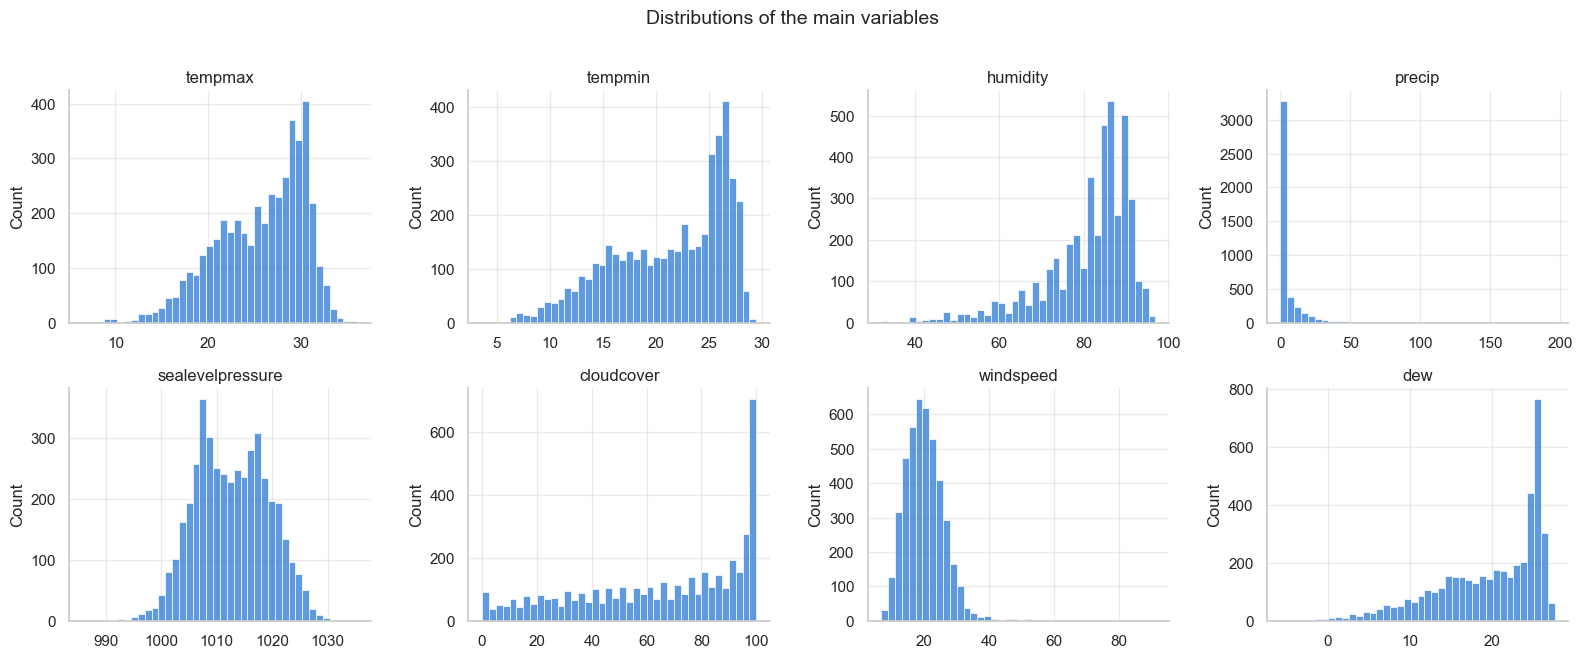

In [11]:
# 5.2 Distributions of the main variables
key_vars = ["tempmax", "tempmin", "humidity", "precip", "sealevelpressure", "cloudcover", "windspeed", "dew"]
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5))
for ax, col in zip(axes.ravel(), key_vars):
    sns.histplot(df[col], bins=40, ax=ax, color=C_BLUE, edgecolor="white", linewidth=0.5)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distributions of the main variables", fontsize=14, y=1.01)
plt.tight_layout(); save_fig("eda_distributions"); plt.show()

Temperatures are left-skewed, reflecting a long hot summer around 28–32 °C and a short mild winter. Precipitation is heavily right-skewed, with most days near 0 mm and a few above 50 mm. Humidity is high almost all year, as expected in a humid subtropical climate, and pressure is higher in winter under the north-east monsoon and lower in summer.

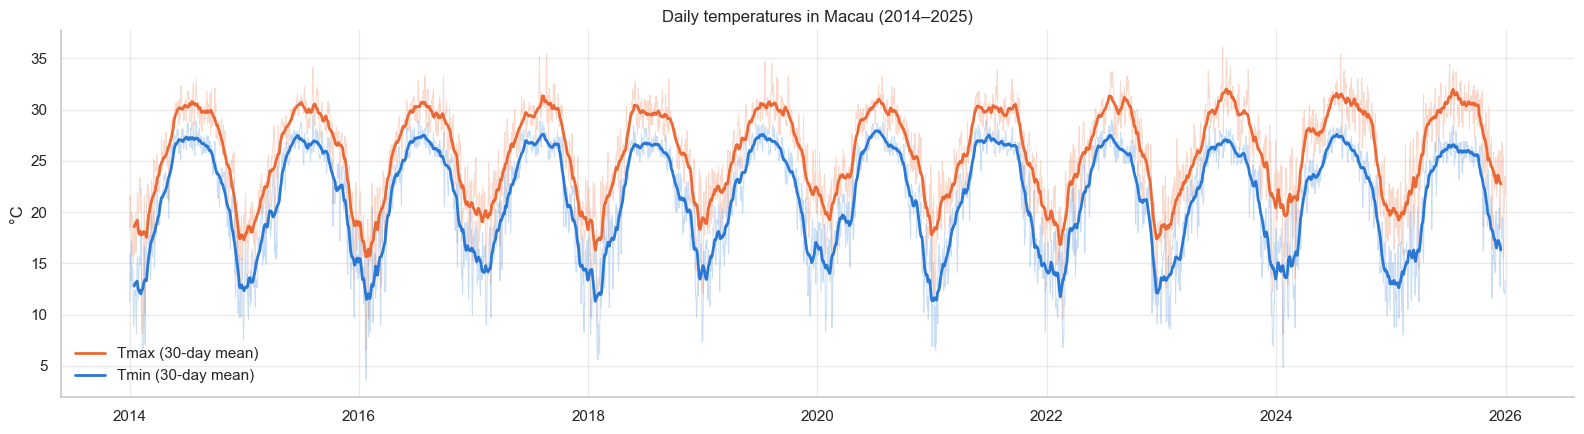

In [12]:
# 5.3 Daily temperatures with a 30-day centred moving average
fig, ax = plt.subplots(figsize=(16, 4.5))
ax.plot(df.index, df["tempmax"], color=C_ORANGE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmin"], color=C_BLUE, alpha=0.25, lw=0.7)
ax.plot(df.index, df["tempmax"].rolling(30, center=True).mean(), color=C_ORANGE, lw=2, label="Tmax (30-day mean)")
ax.plot(df.index, df["tempmin"].rolling(30, center=True).mean(), color=C_BLUE, lw=2, label="Tmin (30-day mean)")
ax.set_ylabel("°C"); ax.set_title(f"Daily temperatures in {LOCATION_NAME} ({START_DATE[:4]}–{END_DATE[:4]})")
ax.legend(loc="lower left", frameon=False)
plt.tight_layout(); save_fig("eda_timeseries_temp"); plt.show()

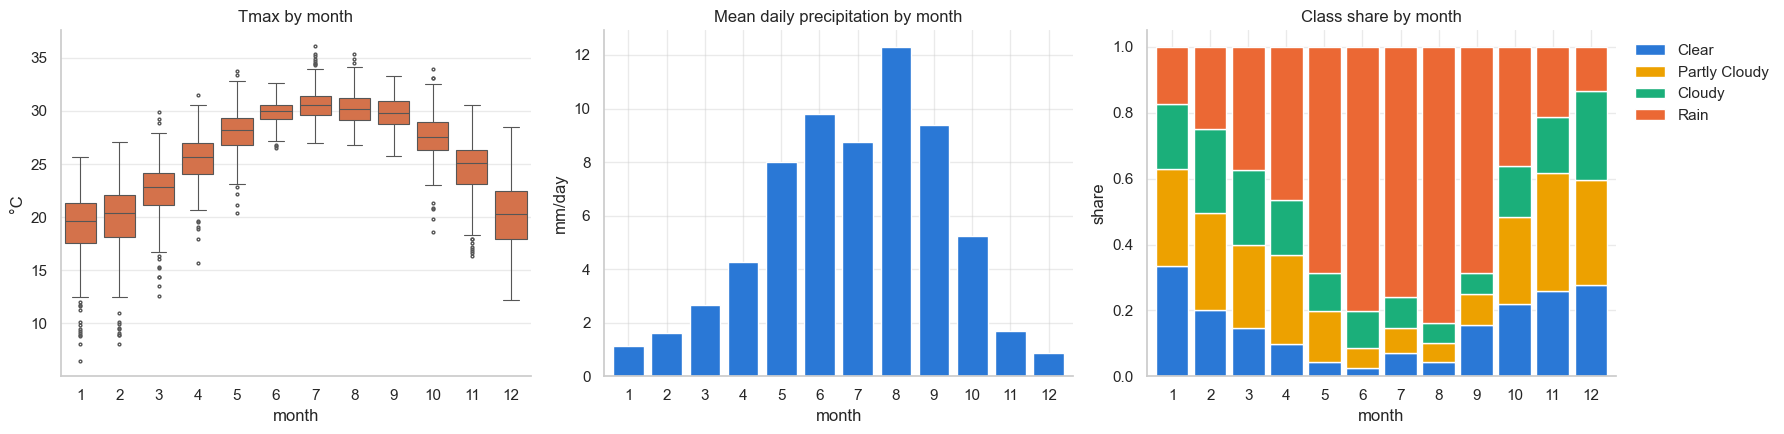

In [13]:
# 5.4 Monthly seasonality of temperature, rainfall and weather classes
tmp = df.assign(month=df.index.month)
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
sns.boxplot(data=tmp, x="month", y="tempmax", ax=axes[0], color=C_ORANGE, fliersize=2, linewidth=0.8)
axes[0].set_title("Tmax by month"); axes[0].set_ylabel("°C"); axes[0].set_xlabel("month")
tmp.groupby("month")["precip"].mean().plot.bar(ax=axes[1], color=C_BLUE, width=0.8, edgecolor="white")
axes[1].set_title("Mean daily precipitation by month"); axes[1].set_ylabel("mm/day"); axes[1].set_xlabel("month")
axes[1].tick_params(axis="x", rotation=0)
prop = pd.crosstab(tmp["month"], tmp["cond_class"], normalize="index")[CLASSES]
prop.plot.bar(stacked=True, ax=axes[2], color=[CLASS_COLORS[c] for c in CLASSES], width=0.85, edgecolor="white", linewidth=1)
axes[2].set_title("Class share by month"); axes[2].set_ylabel("share"); axes[2].set_xlabel("month")
axes[2].tick_params(axis="x", rotation=0)
axes[2].legend(title="", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("eda_seasonality"); plt.show()

Temperature follows a strong annual cycle, peaking in July and August and bottoming out in January and February, which motivates sine and cosine encodings of the day of year. Rain dominates from May to September, the summer monsoon and typhoon season, and is rare in winter, so the month alone carries information about the class. Clear and Partly Cloudy prevail in winter, while dry overcast days are most frequent from December to March.

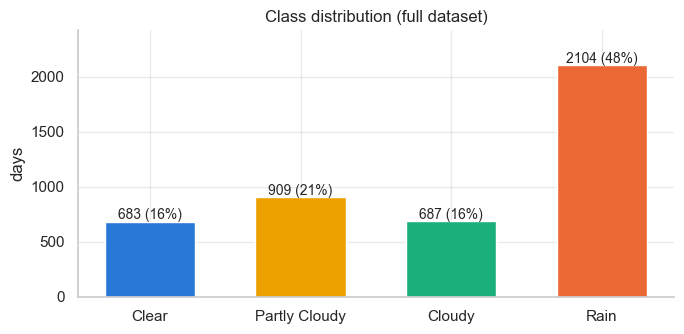

In [14]:
# 5.5 Class balance over the full period
counts = df["cond_class"].value_counts().reindex(CLASSES)
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLORS[c] for c in CLASSES], width=0.6)
for b, v in zip(bars, counts.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 20, f"{v} ({v / counts.sum():.0%})", ha="center", fontsize=10)
ax.set_title("Class distribution (full dataset)"); ax.set_ylabel("days")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout(); save_fig("eda_class_balance"); plt.show()

Rain accounts for 48% of the days, and the other three classes share the rest roughly equally. A model that always predicts Rain would already reach about 48% accuracy, so accuracy is a poor guide here. Macro-averaged F1, which weights the four classes equally, is used as the main classification metric, and the models that support it are trained with `class_weight="balanced"`.

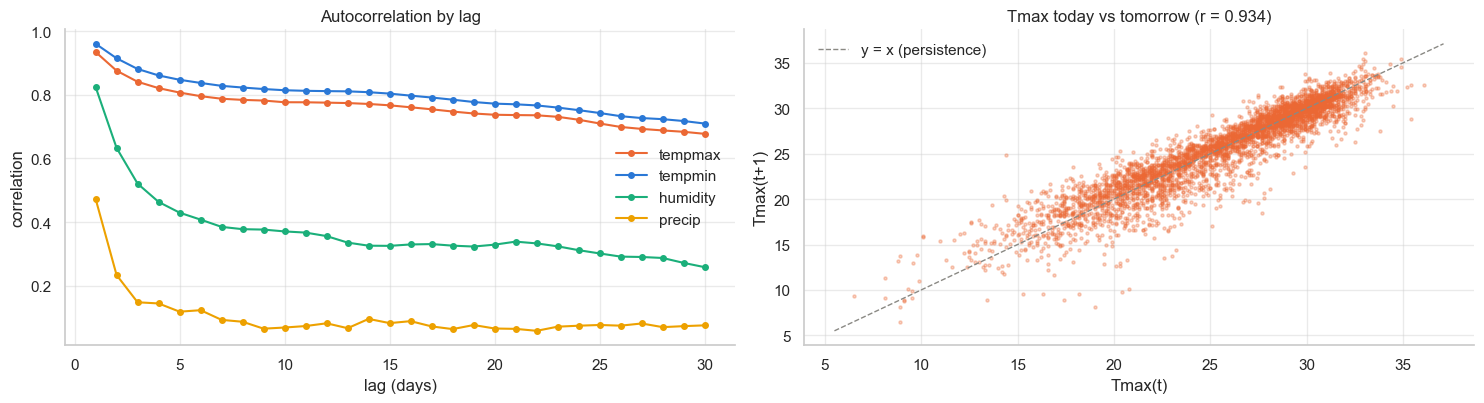

In [15]:
# 5.6 Autocorrelation by lag, and today's Tmax against tomorrow's
lags = range(1, 31)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
for col, color in [("tempmax", C_ORANGE), ("tempmin", C_BLUE), ("humidity", C_AQUA), ("precip", C_YELLOW)]:
    axes[0].plot(list(lags), [df[col].autocorr(l) for l in lags], marker="o", ms=4, color=color, label=col)
axes[0].set_title("Autocorrelation by lag"); axes[0].set_xlabel("lag (days)"); axes[0].set_ylabel("correlation")
axes[0].legend(frameon=False)
axes[1].scatter(df["tempmax"].iloc[:-1], df["tempmax"].shift(-1).iloc[:-1], s=5, alpha=0.3, color=C_ORANGE)
lims = [df["tempmax"].min() - 1, df["tempmax"].max() + 1]
axes[1].plot(lims, lims, color=C_GRAY, ls="--", lw=1, label="y = x (persistence)")
r = df["tempmax"].autocorr(1)
axes[1].set_title(f"Tmax today vs tomorrow (r = {r:.3f})"); axes[1].set_xlabel("Tmax(t)"); axes[1].set_ylabel("Tmax(t+1)")
axes[1].legend(frameon=False)
plt.tight_layout(); save_fig("eda_autocorrelation"); plt.show()

The lag-1 autocorrelation of the maximum temperature is 0.93 and decays slowly, so predicting that tomorrow equals today is already a strong forecast and the persistence baseline will be hard to beat. This memory is what the lagged and rolling features are meant to capture. Precipitation has much weaker autocorrelation, which anticipates that the classification task will be harder than the regression task.

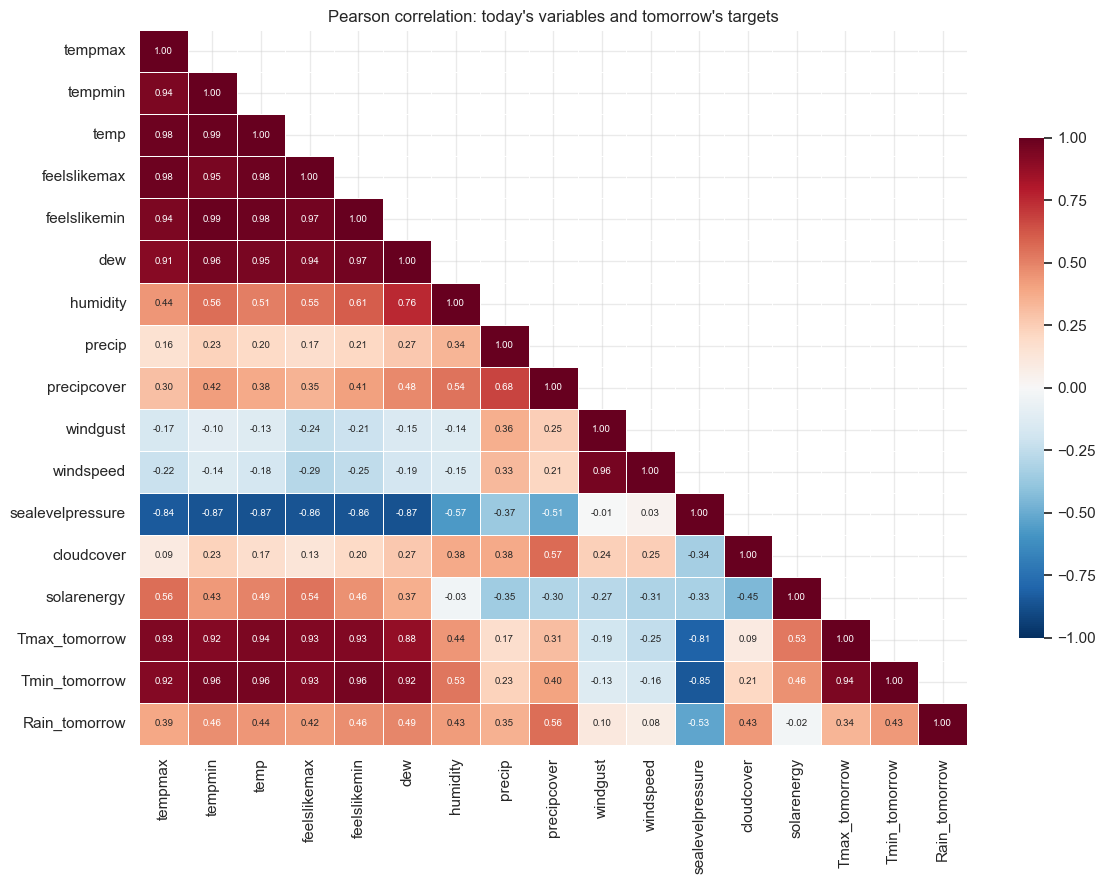

,Tmax_tomorrow,Tmin_tomorrow,Rain_tomorrow
precipcover,0.31,0.40,0.56
dew,0.88,0.92,0.49
tempmin,0.92,0.96,0.46
feelslikemin,0.93,0.96,0.46
temp,0.94,0.96,0.44
cloudcover,0.09,0.21,0.43
humidity,0.44,0.53,0.43
feelslikemax,0.93,0.93,0.42
tempmax,0.93,0.92,0.39
precip,0.17,0.23,0.35


In [16]:
# 5.7 Correlation between today's variables and tomorrow's targets
corr_df = df[NUMERIC_COLS].drop(columns="winddir")
corr_df["Tmax_tomorrow"] = df["tempmax"].shift(-1)
corr_df["Tmin_tomorrow"] = df["tempmin"].shift(-1)
corr_df["Rain_tomorrow"] = (df["cond_class"].shift(-1) == "Rain").astype(float)
corr = corr_df.dropna().corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.5, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Pearson correlation: today's variables and tomorrow's targets")
plt.tight_layout(); save_fig("eda_correlation"); plt.show()

targets = ["Tmax_tomorrow", "Tmin_tomorrow", "Rain_tomorrow"]
corr[targets].drop(targets).sort_values("Rain_tomorrow", ascending=False).round(2)

Tomorrow's temperatures correlate strongly with all of today's temperature variables and with the dew point, and negatively with pressure (r = −0.81 for the maximum), since high pressure in Macau usually means a cold and dry winter air mass. The temperature variables, apparent temperatures and dew point are highly collinear, which calls for regularisation in the linear models but is not a problem for trees. Rain tomorrow is associated with today's precipitation cover, dew point, humidity and cloud cover, and negatively with pressure.

,humidity,sealevelpressure,pressure_change
class_tomorrow,,,
Clear,72.96,1017.13,-0.04
Partly Cloudy,77.77,1015.87,-0.02
Cloudy,78.43,1015.08,0.19
Rain,85.53,1009.04,-0.04


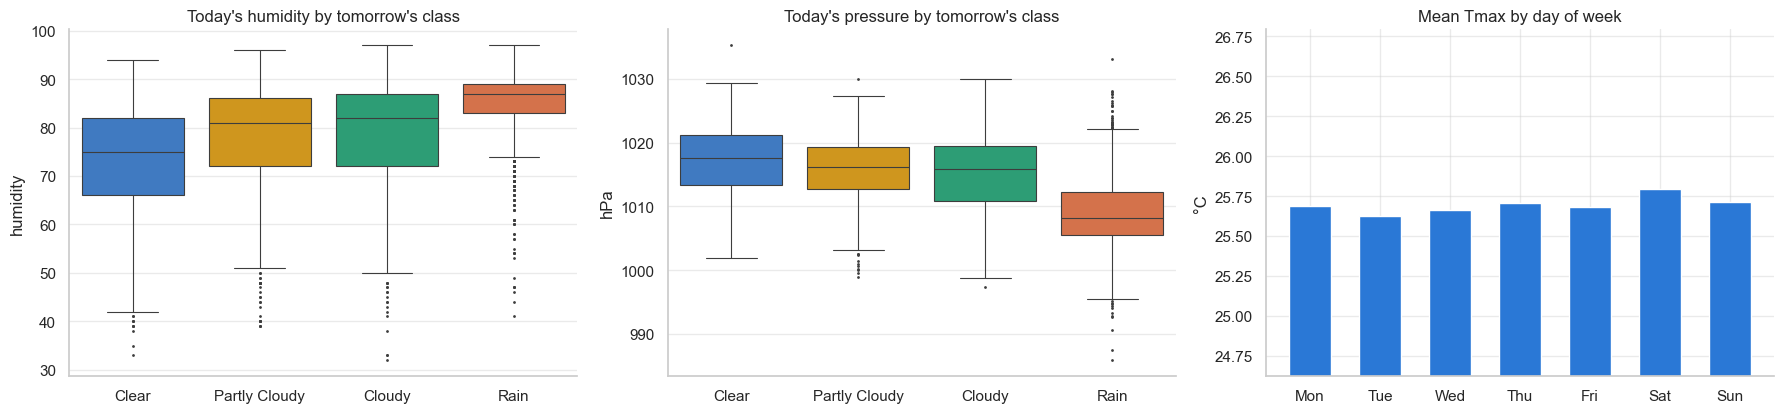

In [17]:
# 5.8 Today's humidity and pressure by tomorrow's class, and a day-of-week check
tmp = df.copy()
tmp["class_tomorrow"] = tmp["cond_class"].shift(-1)
tmp["pressure_change"] = tmp["sealevelpressure"].diff()
tmp = tmp.dropna()
display(tmp.groupby("class_tomorrow")[["humidity", "sealevelpressure", "pressure_change"]].mean().loc[CLASSES].round(2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
pal = [CLASS_COLORS[c] for c in CLASSES]
sns.boxplot(data=tmp, x="class_tomorrow", y="humidity", order=CLASSES, palette=pal, ax=axes[0], fliersize=1, linewidth=0.8)
axes[0].set_title("Today's humidity by tomorrow's class"); axes[0].set_xlabel("")
sns.boxplot(data=tmp, x="class_tomorrow", y="sealevelpressure", order=CLASSES, palette=pal, ax=axes[1], fliersize=1, linewidth=0.8)
axes[1].set_title("Today's pressure by tomorrow's class"); axes[1].set_xlabel(""); axes[1].set_ylabel("hPa")
dow = df.groupby(df.index.dayofweek)["tempmax"].mean()
axes[2].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow.values, color=C_BLUE, width=0.6)
axes[2].set_ylim(dow.min() - 1, dow.max() + 1)
axes[2].set_title("Mean Tmax by day of week"); axes[2].set_ylabel("°C")
plt.tight_layout(); save_fig("eda_relationships"); plt.show()

Days followed by rain have a mean humidity of 85.5% and a mean pressure of 1009 hPa, against 73% and 1017 hPa for days followed by clear skies, so both variables are informative. The day-to-day pressure change barely differs between classes when averaged over the year, but it is kept as a feature because cold fronts and tropical systems do change pressure and the models can decide whether it helps. The mean maximum temperature varies by less than 0.2 °C across days of the week, so the day of week, suggested in the specification as a calendar feature, was not used. Hour of day does not apply to daily data.

---
## 6. Feature engineering

To predict day t+1, each feature uses only information available at the end of day t: today's values and earlier days. The targets are tomorrow's values, obtained with `shift(-1)`. The feature groups and the reasoning behind them are listed below; the code is in `wu.build_features`.

| Group | Features | Rationale |
|---|---|---|
| Today (14) | the measured variables of day t | the current state is the best single predictor of tomorrow |
| Lags (20) | values at t−1 and t−2 | capture whether conditions are warming, cooling, drying or moistening |
| Differences (5) | day-to-day change in Tmax, Tmin, humidity; 1- and 3-day pressure change | short-term tendency; pressure changes accompany fronts |
| Rolling statistics (24) | 3, 7 and 14-day means, 7-day standard deviations, rain days in the last week | smooth daily noise and describe the recent regime |
| Physical (3) | diurnal range, dew-point depression, anomaly from the 30-day mean | a small dew-point depression signals saturated air |
| Seasonality (4) | sine and cosine of day of year and month | make 31 December and 1 January neighbours |
| Wind (2) | sine and cosine of wind direction | 359° and 1° are almost the same direction |
| Today's class (4) | one-hot indicators | persistence of the weather type without imposing an order |

Scale-sensitive models (linear models, KNN and SVM) receive a `StandardScaler` inside a pipeline, so the scaling is fitted on the training data of each step only. Tree-based models are used without scaling.

In [18]:
# 6.1 Feature matrix and targets
feat, FEATURES = wu.build_features(df)
print(f"Feature matrix: {feat.shape[0]} rows, {len(FEATURES)} features")
feat.to_csv(PROCESSED_DIR / "macau_features_processed.csv")
feat[FEATURES[:6] + ["tempmax_lag1", "tempmax_roll7", "doy_sin", "target_tmax", "target_tmin", "target_cond"]].head()

Feature matrix: 4353 rows, 76 features


,tempmax,tempmin,temp,feelslikemax,feelslikemin,dew,tempmax_lag1,tempmax_roll7,doy_sin,target_tmax,target_tmin,target_cond
date,,,,,,,,,,,,
2014-01-30,20.1,12.2,16.6,21.6,12.2,14.2,20.7,20.028571,0.493468,21.7,14.4,Clear
2014-01-31,21.7,14.4,17.9,23.0,15.5,15.5,20.1,20.442857,0.508356,21.6,15.2,Partly Cloudy
2014-02-01,21.6,15.2,18.4,23.0,16.3,16.6,21.7,20.671429,0.523094,21.8,15.6,Partly Cloudy
2014-02-02,21.8,15.6,18.3,24.0,16.9,16.4,21.6,20.657143,0.537677,23.4,15.4,Clear
2014-02-03,23.4,15.4,19.2,26.0,15.5,15.5,21.8,21.271429,0.552101,21.2,14.9,Partly Cloudy


In [19]:
# 6.2 Leakage checks: the target of day t must equal tempmax of day t+1,
#     and no feature may be a copy of the target
check = (feat["target_tmax"].iloc[:-1].values == df.loc[feat.index[1:], "tempmax"].values).mean()
max_corr = feat[FEATURES].corrwith(feat["target_tmax"]).abs().max()
print(f"target_tmax(t) == tempmax(t+1) in {check:.1%} of rows; highest |correlation| feature-target: {max_corr:.3f}")
assert check > 0.99 and max_corr < 0.999

target_tmax(t) == tempmax(t+1) in 100.0% of rows; highest |correlation| feature-target: 0.939


---
## 7. Chronological split

A random split would let the models train on days that come after the days they are evaluated on, which inflates the scores. The data is split into consecutive blocks by target date, so no label from a later period is used to fit a model evaluated on an earlier one. Validation and test each cover two full years, including all seasons and two typhoon seasons.

| Set | Target period | Use |
|---|---|---|
| Train | 2014–2021 | fitting the models and the grid search |
| Validation | 2022–2023 | comparing models and choosing the final one |
| Test | 2024–2025 | a single final evaluation |

Train     :  2892 rows | targets 2014-01-31 to 2021-12-31
Validation:   730 rows | targets 2022-01-01 to 2023-12-31
Test      :   731 rows | targets 2024-01-01 to 2025-12-31


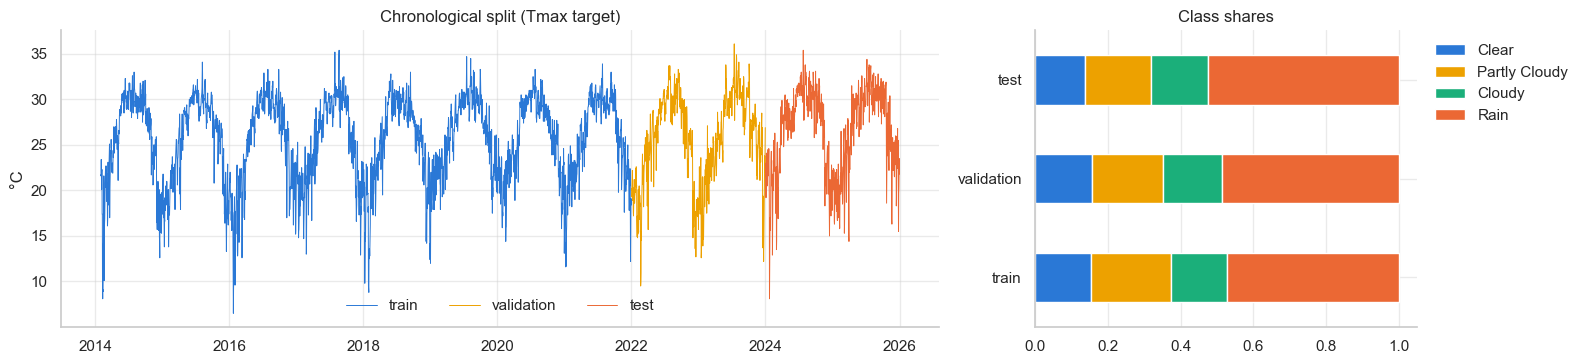

In [20]:
# 7.1 Split by target date and check that the class shares are similar across sets
td = feat["target_date"]
train, val, test = feat[td <= TRAIN_END], feat[(td > TRAIN_END) & (td <= VAL_END)], feat[td > VAL_END]
for name, part in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:10s}: {len(part):5d} rows | targets {part['target_date'].min().date()} to {part['target_date'].max().date()}")
X_train, X_val, X_test = train[FEATURES], val[FEATURES], test[FEATURES]

fig, axes = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2.3, 1]})
for part, color, lab in [(train, C_BLUE, "train"), (val, C_YELLOW, "validation"), (test, C_ORANGE, "test")]:
    axes[0].plot(part["target_date"], part["target_tmax"], color=color, lw=0.7, label=lab)
axes[0].set_title("Chronological split (Tmax target)"); axes[0].set_ylabel("°C"); axes[0].legend(frameon=False, ncol=3)
dist = pd.DataFrame({n: p["target_cond"].value_counts(normalize=True) for n, p in
                     [("train", train), ("validation", val), ("test", test)]}).loc[CLASSES].T
dist.plot.barh(stacked=True, ax=axes[1], color=[CLASS_COLORS[c] for c in CLASSES], edgecolor="white", linewidth=1)
axes[1].set_title("Class shares"); axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout(); save_fig("split"); plt.show()

---
## 8. Task 1 – Regression of tomorrow's Tmax and Tmin

Mean absolute error (MAE) in °C is the main metric because it is easy to interpret and robust to outliers. RMSE is reported because it penalises large misses, such as an unforecast cold front, and R² and Pearson's r describe how much variance is explained and how well the forecast follows rises and falls.

The official baseline is persistence, which predicts that tomorrow's temperature equals today's. Climatology, the training mean for the same day of the year smoothed over 15 days, is added as a second reference to show how much is gained by looking at the current state rather than only at the calendar. Nine regressors from different families are compared: linear regression, Ridge and Lasso; k-nearest neighbours; support vector regression with an RBF kernel; random forest and extra trees; and gradient boosting and histogram gradient boosting. One model is trained per target because the physics differs: the maximum depends more on sunshine and cloud during the day, the minimum more on humidity and the air mass at night.

In [21]:
# 8.1 Targets: target column -> (today's column used by persistence, label)
REG_TARGETS = {"target_tmax": ("tempmax", "Tmax"), "target_tmin": ("tempmin", "Tmin")}

In [22]:
# 8.2 Baselines and nine regressors: fit on train, evaluate on validation, sorted by MAE
reg_val_pred, rows = {}, []
for target, (today_col, label) in REG_TARGETS.items():
    preds = {"Persistence": val[today_col].values,
             "Climatology": wu.climatology_predict(train, val, target)}
    secs = {}
    for name, model in wu.make_regressors(SEED).items():
        t0 = time.time()
        preds[name] = model.fit(X_train, train[target]).predict(X_val)
        secs[name] = time.time() - t0
    reg_val_pred |= {(target, n): p for n, p in preds.items()}
    rows += [{"target": label, "model": n, **wu.regression_metrics(val[target], p), "train_time_s": secs.get(n, 0.0)}
             for n, p in preds.items()]
reg_val_table = pd.DataFrame(rows).sort_values(["target", "MAE"]).set_index(["target", "model"]).round(3)
reg_val_table

MAE   RMSE     R2  Pearson_r  train_time_s
target model                                                         
Tmax   GradientBoosting  1.032  1.346  0.926      0.964         6.412
       Ridge             1.033  1.348  0.926      0.963         0.002
       LinearRegression  1.034  1.348  0.926      0.963         0.006
       ExtraTrees        1.048  1.384  0.922      0.962         0.368
       Lasso             1.049  1.375  0.923      0.962         0.034
       HistGradBoost     1.054  1.377  0.922      0.962         1.510
       RandomForest      1.058  1.401  0.920      0.961         0.977
       SVR               1.139  1.504  0.908      0.955         0.345
       KNN               1.217  1.599  0.895      0.950         0.027
       Persistence       1.244  1.716  0.880      0.940         0.000
       Climatology       1.826  2.399  0.765      0.875         0.000
Tmin   HistGradBoost     0.993  1.375  0.936      0.968         1.666
       RandomForest      1.000  1.380  0.935      0.967         1.123
       ExtraTrees        1.000  1.386  0.935      0.967         0.456
       GradientBoosting  1.008  1.405  0.933      0.966         6.471
       LinearRegression  1.008  1.398  0.934      0.967         0.006
       Ridge             1.009  1.396  0.934      0.967         0.002
       Lasso             1.011  1.407  0.933      0.966         0.013
       SVR               1.041  1.465  0.927      0.964         0.362
       Persistence       1.101  1.614  0.912      0.956         0.000
       KNN               1.160  1.615  0.912      0.960         0.007
       Climatology       1.756  2.376  0.809      0.902         0.000

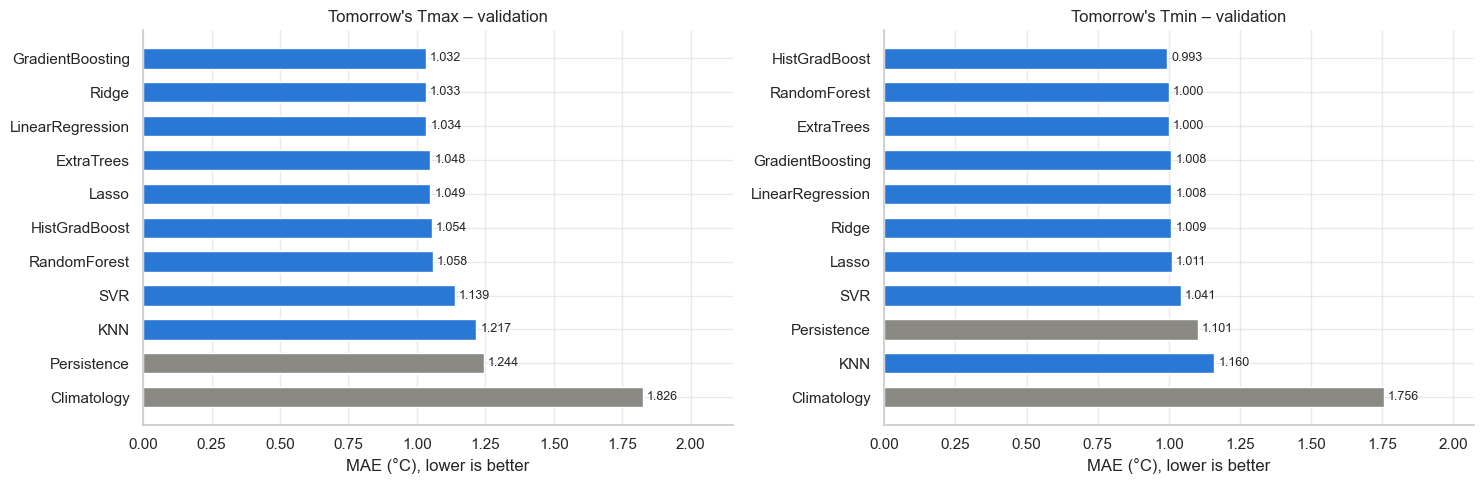

Tmax: best model GradientBoosting (MAE 1.032), 17.0% below persistence (1.244)
Tmin: best model HistGradBoost (MAE 0.993), 9.8% below persistence (1.101)


In [23]:
# 8.3 Validation MAE of every model (references in grey)
BASELINES = ["Persistence", "Climatology", "Majority"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, label in zip(axes, ["Tmax", "Tmin"]):
    vals = reg_val_table.loc[label, "MAE"]
    bars = ax.barh(vals.index, vals.values, height=0.6, color=[C_GRAY if n in BASELINES else C_BLUE for n in vals.index])
    ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
    ax.invert_yaxis(); ax.set_xlim(0, vals.max() * 1.18)
    ax.set_xlabel("MAE (°C), lower is better"); ax.set_title(f"Tomorrow's {label} – validation")
plt.tight_layout(); save_fig("reg_val_comparison"); plt.show()

for label in ["Tmax", "Tmin"]:
    t = reg_val_table.loc[label, "MAE"]
    best = t.drop(BASELINES, errors="ignore").idxmin()
    print(f"{label}: best model {best} (MAE {t[best]:.3f}), {1 - t[best] / t['Persistence']:.1%} below persistence ({t['Persistence']:.3f})")

Almost every model beats persistence on validation; the exception is KNN for the minimum temperature. Gradient boosting is best for the maximum (1.032 °C against 1.244 °C for persistence, 17% lower) and histogram gradient boosting for the minimum (0.993 °C against 1.101 °C, 10% lower). Climatology is far behind at about 1.8 °C, which shows that the calendar alone is not enough. The leading models are separated by hundredths of a degree: for the maximum, gradient boosting, Ridge and linear regression score 1.032, 1.033 and 1.034 °C, although Ridge trains in milliseconds and gradient boosting in about six seconds. The relationship between today's state and tomorrow's temperature is therefore close to linear once the features are in place. KNN and SVR trail the others, as distance-based similarity loses meaning with 76 features.

### Hyperparameter tuning

The best model for each target is tuned with `GridSearchCV` on the training set, using five time-ordered folds (`TimeSeriesSplit` with a one-day gap). Each fold trains on the past and validates on the period that immediately follows; an ordinary shuffled k-fold would let the model learn from the future. The one-day gap prevents the target of the last training day from appearing as a feature of the first validation day. The grids, defined in `wu.REG_PARAM_GRIDS`, have at most 27 combinations, so an exhaustive search is affordable. MAE is the objective.

In [24]:
# 8.4 Grid search with five time-ordered folds for the best model of each target
reg_best_name, reg_tuned = {}, {}
for target, (_, label) in REG_TARGETS.items():
    cand = reg_val_table.loc[label].drop(BASELINES, errors="ignore")
    best = reg_best_name[target] = cand["MAE"].idxmin()
    search = wu.tune_model(wu.make_regressors(SEED)[best], wu.REG_PARAM_GRIDS[best], X_train, train[target],
                           "neg_mean_absolute_error")
    reg_tuned[target] = search.best_estimator_
    reg_val_pred[(target, best + "_tuned")] = pred = search.best_estimator_.predict(X_val)
    print(f"{label}: {best}, best parameters {wu.fmt_params(search.best_params_)}\n"
          f"  CV MAE (train) {-search.best_score_:.3f} | validation MAE {cand.loc[best, 'MAE']:.3f} -> "
          f"{mean_absolute_error(val[target], pred):.3f}")

Tmax: GradientBoosting, best parameters {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200}
  CV MAE (train) 1.012 | validation MAE 1.032 -> 1.035


Tmin: HistGradBoost, best parameters {'learning_rate': 0.02, 'max_iter': 300, 'max_leaf_nodes': 15, 'min_samples_leaf': 20}
  CV MAE (train) 0.925 | validation MAE 0.993 -> 0.991


Tuning did not help on validation: the maximum-temperature model went from 1.032 to 1.035 °C with 200 instead of 300 trees, and the minimum-temperature model from 0.993 to 0.991 °C. The default settings were already reasonable, and the configuration that is best on the 2014–2021 folds is not necessarily best for 2022–2023, a sign of some drift between periods. The tuned model is therefore compared with an ensemble before choosing the final model.

### Ensemble

The ensemble averages the tuned model with the second- and third-best models on validation (`VotingRegressor`). Models from different families tend to make different errors, and averaging cancels part of them. The final model for each target is whichever of the tuned model and the ensemble has the lower validation MAE, a rule fixed before looking at the test set.

In [25]:
# 8.5 Ensemble of the top three models and choice of the final model
reg_final_spec, rows = {}, []
for target, (_, label) in REG_TARGETS.items():
    best = reg_best_name[target]
    runners_up = reg_val_table.loc[label, "MAE"].drop(BASELINES + [best], errors="ignore").index[:2]
    members = {n: wu.make_regressors(SEED)[n] for n in runners_up} | {best + "_tuned": reg_tuned[target]}
    reg_val_pred[(target, "Ensemble")] = wu.ensemble(members).fit(X_train, train[target]).predict(X_val)
    rows += [{"target": label, "model": n, **wu.regression_metrics(val[target], reg_val_pred[(target, n)])}
             for n in [best + "_tuned", "Ensemble"]]
    final = "Ensemble" if rows[-1]["MAE"] < rows[-2]["MAE"] else best + "_tuned"
    reg_final_spec[target] = (final, wu.ensemble(members) if final == "Ensemble" else clone(reg_tuned[target]))   # unfitted, refit on train+validation
    print(f"{label}: members {list(members)}")
    print(f"{label}: validation MAE {best}_tuned {rows[-2]['MAE']:.3f} | Ensemble {rows[-1]['MAE']:.3f} -> final: {final}")

reg_val_full = pd.concat([reg_val_table, pd.DataFrame(rows).set_index(["target", "model"]).round(3)]).sort_index(level=0, sort_remaining=False)
reg_val_full.to_csv(RESULTS_DIR / "regression_validation_results.csv")
reg_val_full

Tmax: members ['Ridge', 'LinearRegression', 'GradientBoosting_tuned']
Tmax: validation MAE GradientBoosting_tuned 1.035 | Ensemble 1.011 -> final: Ensemble


Tmin: members ['RandomForest', 'ExtraTrees', 'HistGradBoost_tuned']
Tmin: validation MAE HistGradBoost_tuned 0.991 | Ensemble 0.988 -> final: Ensemble


MAE   RMSE     R2  Pearson_r  train_time_s
target model                                                               
Tmax   GradientBoosting        1.032  1.346  0.926      0.964         6.412
       Ridge                   1.033  1.348  0.926      0.963         0.002
       LinearRegression        1.034  1.348  0.926      0.963         0.006
       ExtraTrees              1.048  1.384  0.922      0.962         0.368
       Lasso                   1.049  1.375  0.923      0.962         0.034
       HistGradBoost           1.054  1.377  0.922      0.962         1.510
       RandomForest            1.058  1.401  0.920      0.961         0.977
       SVR                     1.139  1.504  0.908      0.955         0.345
       KNN                     1.217  1.599  0.895      0.950         0.027
       Persistence             1.244  1.716  0.880      0.940         0.000
       Climatology             1.826  2.399  0.765      0.875         0.000
       GradientBoosting_tuned  1.035  1.357  0.925      0.963           NaN
       Ensemble                1.011  1.321  0.929      0.965           NaN
Tmin   HistGradBoost           0.993  1.375  0.936      0.968         1.666
       RandomForest            1.000  1.380  0.935      0.967         1.123
       ExtraTrees              1.000  1.386  0.935      0.967         0.456
       GradientBoosting        1.008  1.405  0.933      0.966         6.471
       LinearRegression        1.008  1.398  0.934      0.967         0.006
       Ridge                   1.009  1.396  0.934      0.967         0.002
       Lasso                   1.011  1.407  0.933      0.966         0.013
       SVR                     1.041  1.465  0.927      0.964         0.362
       Persistence             1.101  1.614  0.912      0.956         0.000
       KNN                     1.160  1.615  0.912      0.960         0.007
       Climatology             1.756  2.376  0.809      0.902         0.000
       HistGradBoost_tuned     0.991  1.377  0.936      0.968           NaN
       Ensemble                0.988  1.368  0.937      0.968           NaN

The ensemble is the best option for both targets, with a validation MAE of 1.011 °C for the maximum and 0.988 °C for the minimum. For the maximum it combines tuned gradient boosting with Ridge and linear regression, and mixing boosted trees with linear models brings the error down from 1.035 to 1.011 °C. For the minimum the three best models are all tree ensembles, whose errors are more alike, and the gain is smaller (0.991 to 0.988 °C).

### Final evaluation on the test set

The final model is refitted on training and validation data together and evaluated once on 2024–2025; nothing is changed afterwards. To judge whether the improvement over persistence is real, a moving block bootstrap with 7-day blocks and 2000 resamples gives a 95% confidence interval for the reduction in MAE. Resampling blocks rather than single days preserves the autocorrelation of the errors.

In [26]:
# 8.6 Refit on train+validation, single test evaluation and block bootstrap against persistence
trainval = pd.concat([train, val])
rows, reg_test_pred = [], {}
for target, (today_col, label) in REG_TARGETS.items():
    final_name, recipe = reg_final_spec[target]
    final_model = recipe.fit(trainval[FEATURES], trainval[target])
    preds = reg_test_pred[target] = {"Persistence": test[today_col].values,
                                     "Climatology": wu.climatology_predict(trainval, test, target),
                                     f"FINAL ({final_name})": final_model.predict(X_test)}
    rows += [{"target": label, "model": n, **wu.regression_metrics(test[target], p)} for n, p in preds.items()]
    lo, hi = wu.block_bootstrap_diff(test[target], preds[f"FINAL ({final_name})"], preds["Persistence"], mean_absolute_error)
    print(f"{label}: MAE reduction vs persistence, 95% CI [{lo:.3f}, {hi:.3f}] °C -> {'significant' if lo > 0 else 'not significant'}")
    joblib.dump(final_model, MODELS_DIR / f"final_regressor_{label}.joblib")

reg_test_table = pd.DataFrame(rows).set_index(["target", "model"]).round(3)
reg_test_table.to_csv(RESULTS_DIR / "regression_test_results.csv")
reg_test_table

Tmax: MAE reduction vs persistence, 95% CI [0.211, 0.356] °C -> significant


Tmin: MAE reduction vs persistence, 95% CI [0.072, 0.173] °C -> significant


MAE   RMSE     R2  Pearson_r
target model                                           
Tmax   Persistence       1.510  2.060  0.808      0.904
       Climatology       2.139  2.676  0.677      0.853
       FINAL (Ensemble)  1.220  1.605  0.884      0.942
Tmin   Persistence       1.107  1.582  0.912      0.956
       Climatology       1.790  2.380  0.800      0.895
       FINAL (Ensemble)  0.987  1.382  0.933      0.967

Tmax: winter (Nov-Mar) MAE persistence 1.91 -> model 1.43 | summer (May-Sep) persistence 1.10 -> model 0.97
Tmin: winter (Nov-Mar) MAE persistence 1.50 -> model 1.31 | summer (May-Sep) persistence 0.72 -> model 0.68


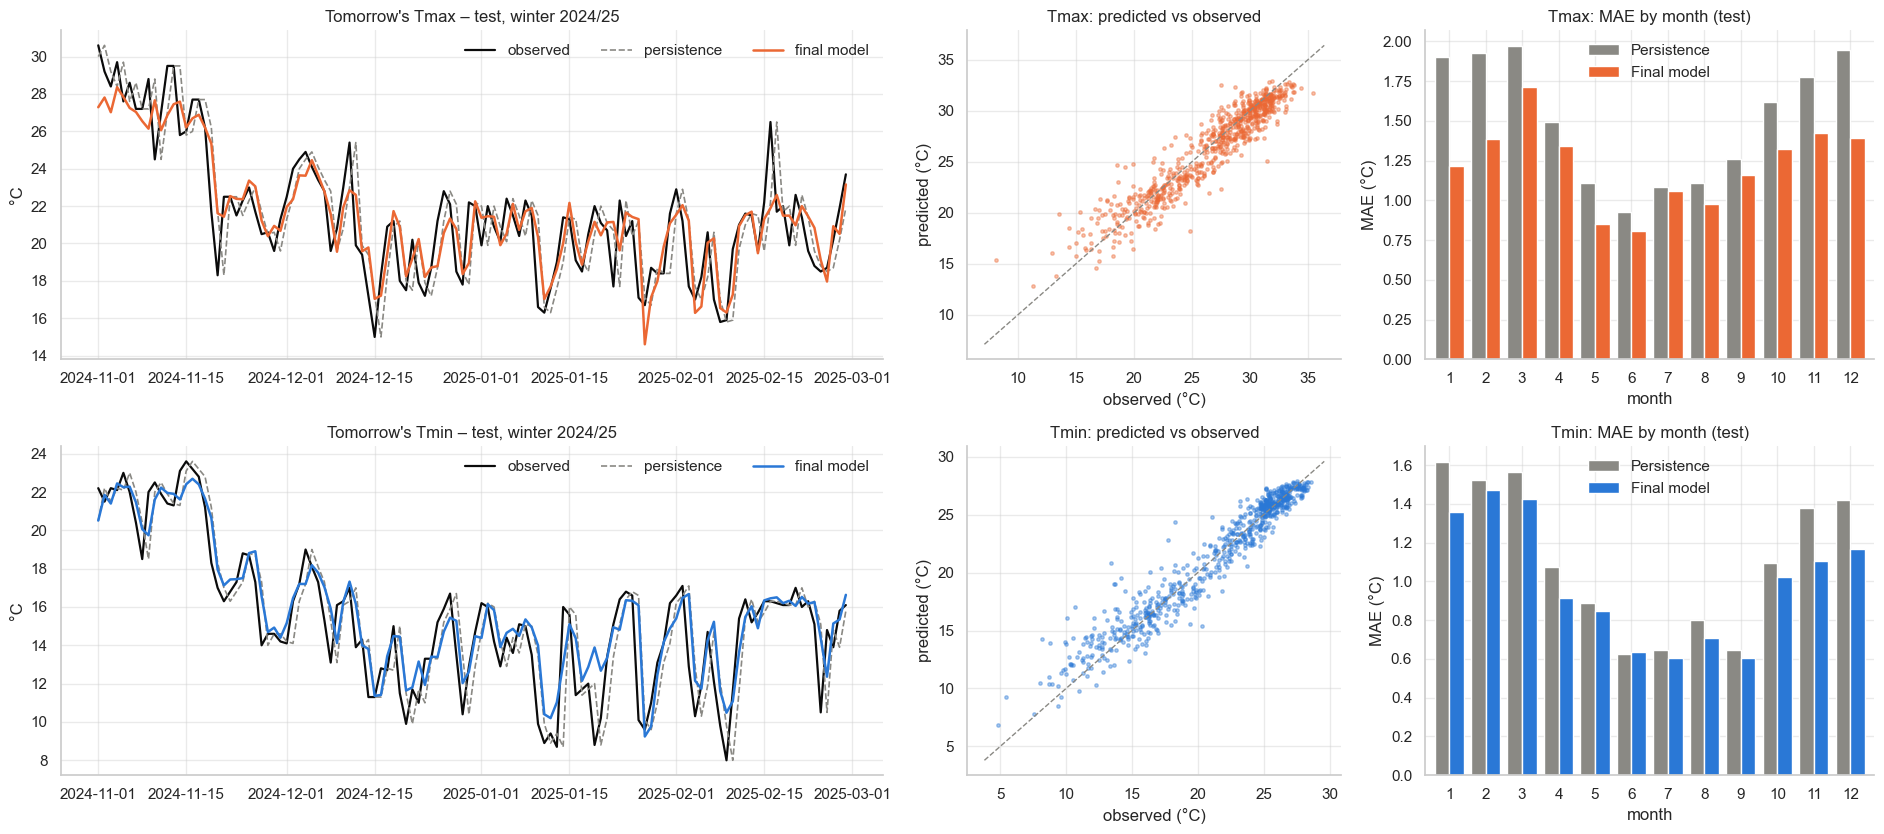

In [27]:
# 8.7 Test results: winter 2024/25 series, predicted vs observed, and MAE by month
fig, axes = plt.subplots(2, 3, figsize=(19, 8.5), gridspec_kw={"width_ratios": [2.2, 1, 1.2]})
for row, (target, (today_col, label)) in enumerate(REG_TARGETS.items()):
    preds = reg_test_pred[target]
    fname = [k for k in preds if k.startswith("FINAL")][0]
    dates, y_te = test["target_date"], test[target]
    color = C_ORANGE if label == "Tmax" else C_BLUE

    win = (dates >= "2024-11-01") & (dates < "2025-03-01")      # winter, when changes are most abrupt
    ax = axes[row, 0]
    ax.plot(dates[win], y_te[win], color="#0b0b0b", lw=1.6, label="observed")
    ax.plot(dates[win], preds["Persistence"][win.values], color=C_GRAY, lw=1.2, ls="--", label="persistence")
    ax.plot(dates[win], preds[fname][win.values], color=color, lw=1.8, label="final model")
    ax.set_title(f"Tomorrow's {label} – test, winter 2024/25"); ax.set_ylabel("°C"); ax.legend(frameon=False, ncol=3)

    ax = axes[row, 1]
    ax.scatter(y_te, preds[fname], s=6, alpha=0.4, color=color)
    lims = [y_te.min() - 1, y_te.max() + 1]
    ax.plot(lims, lims, color=C_GRAY, ls="--", lw=1)
    ax.set_title(f"{label}: predicted vs observed"); ax.set_xlabel("observed (°C)"); ax.set_ylabel("predicted (°C)")

    ax = axes[row, 2]
    err = pd.DataFrame({"month": dates.dt.month.values,
                        "Persistence": np.abs(y_te.values - preds["Persistence"]),
                        "Final model": np.abs(y_te.values - preds[fname])}).groupby("month").mean()
    err.plot.bar(ax=ax, color=[C_GRAY, color], width=0.8, edgecolor="white")
    ax.set_title(f"{label}: MAE by month (test)"); ax.set_ylabel("MAE (°C)"); ax.set_xlabel("month")
    ax.tick_params(axis="x", rotation=0); ax.legend(frameon=False)
    winter, summer = err.loc[[11, 12, 1, 2, 3]].mean(), err.loc[[5, 6, 7, 8, 9]].mean()
    print(f"{label}: winter (Nov-Mar) MAE persistence {winter['Persistence']:.2f} -> model {winter['Final model']:.2f} | "
          f"summer (May-Sep) persistence {summer['Persistence']:.2f} -> model {summer['Final model']:.2f}")
plt.tight_layout(); save_fig("reg_test_results"); plt.show()

On the test set the final model lowers the MAE by 19% for the maximum temperature (1.51 to 1.22 °C) and by 11% for the minimum (1.11 to 0.99 °C). The bootstrap intervals for the reduction, [0.21, 0.36] °C and [0.07, 0.17] °C, exclude zero, so both improvements are statistically significant. The test error for the minimum agrees with the validation estimate (0.988 °C), which suggests the model selection did not overfit the validation period.

Most of the gain comes in winter, when cold fronts cause sharp drops: from November to March the error for the maximum falls from 1.91 to 1.43 °C, compared with 1.10 to 0.97 °C in the more stable summer. In the winter series persistence is simply the observed curve shifted by one day, while the model anticipates part of each change. It still smooths the peaks and troughs, a typical consequence of minimising the average error.

### Feature importance

Importance is measured by permutation on the validation set: each feature is shuffled in turn and the increase in MAE is recorded. The method works with any model and is computed outside the training data, unlike impurity-based importance, which favours continuous features. The tuned model fitted on the training set is used so that the test set is not touched.

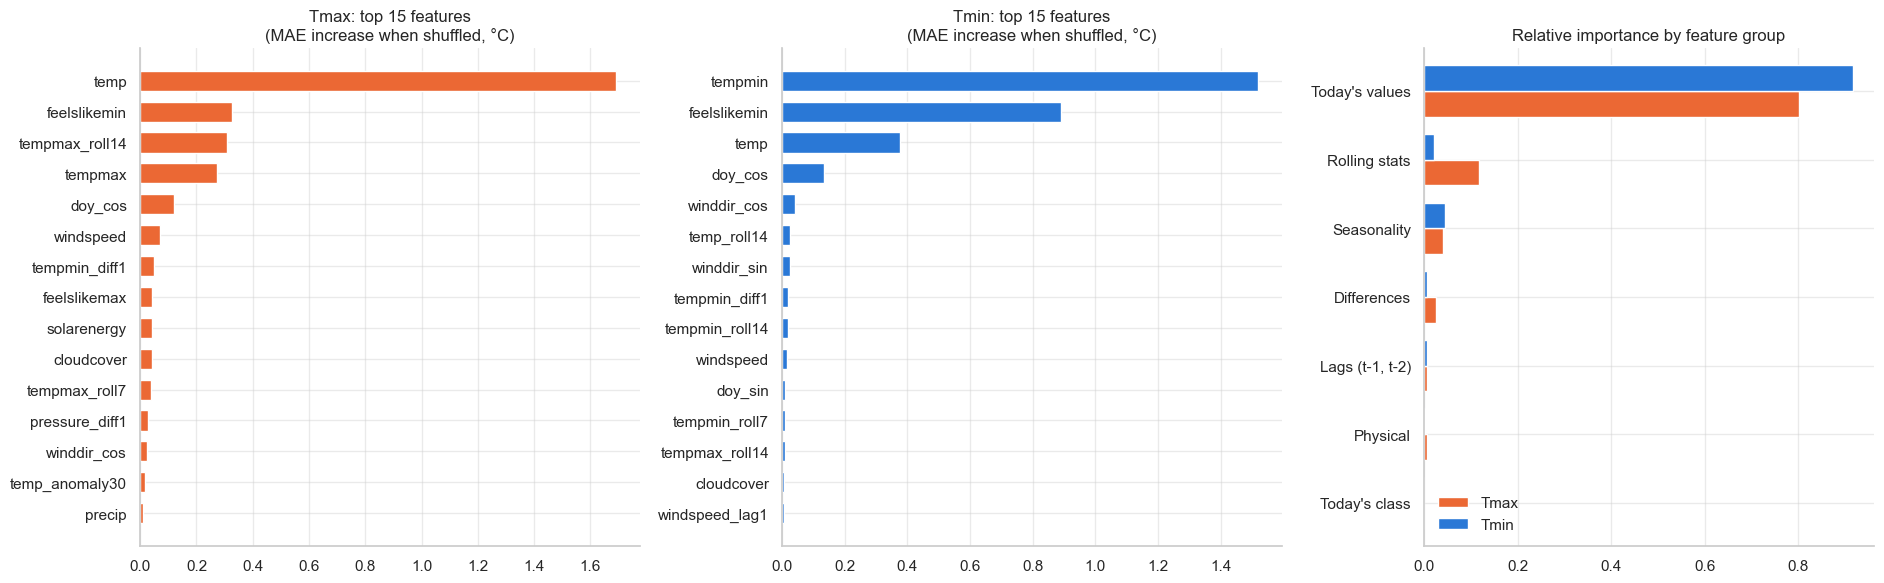

In [28]:
# 8.8 Permutation importance on validation, by feature and by feature group
fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1, 1, 0.9]})
group_imp = {}
for ax, (target, (_, label)) in zip(axes[:2], REG_TARGETS.items()):
    pi = permutation_importance(reg_tuned[target], X_val, val[target], scoring="neg_mean_absolute_error",
                                n_repeats=5, random_state=SEED, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)
    group_imp[label] = imp.clip(lower=0).groupby(imp.index.map(wu.feature_group)).sum()
    top = imp.head(15)[::-1]
    ax.barh(top.index, top.values, color=C_ORANGE if label == "Tmax" else C_BLUE, height=0.65)
    ax.set_title(f"{label}: top 15 features\n(MAE increase when shuffled, °C)")
gi = pd.DataFrame(group_imp)
(gi / gi.sum()).sort_values("Tmax").plot.barh(ax=axes[2], color=[C_ORANGE, C_BLUE], width=0.75)
axes[2].set_title("Relative importance by feature group"); axes[2].legend(frameon=False)
plt.tight_layout(); save_fig("reg_feature_importance"); plt.show()

Today's values dominate for both targets: mean temperature, minimum apparent temperature and maximum temperature for Tmax, and minimum temperature, minimum apparent temperature and mean temperature for Tmin. They are followed by the 14-day rolling mean, the seasonal terms and the day-to-day differences. For the maximum, wind speed and the drop in minimum temperature also matter, both typical of an incoming north-east monsoon surge. Because the temperature variables are highly correlated, they share importance among themselves: shuffling one changes little while the others carry the same information. The group totals on the right are therefore more reliable than the individual ranking.

---
## 9. Task 2 – Classification of tomorrow's weather condition

Macro F1 is the main metric, since it gives the four classes equal weight and is not inflated by the majority class. Accuracy, balanced accuracy and weighted F1 are reported alongside, together with per-class precision and recall and the confusion matrix, which show where the classes are confused.

The official baseline always predicts the most frequent training class (Rain). Persistence of the condition, which predicts that tomorrow will look like today, is a much stronger reference. Eight classifiers are compared: logistic regression, KNN, SVC with an RBF kernel, Gaussian naive Bayes, random forest, extra trees, gradient boosting and histogram gradient boosting. Logistic regression, SVC, random forest, extra trees and histogram gradient boosting use balanced class weights, which raise the cost of errors on the rarer classes without creating synthetic samples; KNN, naive Bayes and gradient boosting do not offer this option.

In [29]:
# 9.1 Classification targets
y_train_c, y_val_c, y_test_c = train["target_cond"], val["target_cond"], test["target_cond"]

In [30]:
# 9.2 Baselines and eight classifiers: fit on train, evaluate on validation, sorted by macro F1
majority = y_train_c.mode()[0]
clf_val_pred = {"Majority": np.full(len(val), majority), "Persistence": wu.persistence_class(val)}
secs = {}
for name, model in wu.make_classifiers(SEED).items():
    t0 = time.time()
    clf_val_pred[name] = model.fit(X_train, y_train_c).predict(X_val)
    secs[name] = time.time() - t0
print(f"Majority class in train: {majority}")
clf_val_table = pd.DataFrame({n: {**wu.classification_metrics(y_val_c, p), "train_time_s": secs.get(n, 0.0)}
                              for n, p in clf_val_pred.items()}).T.sort_values("F1_macro", ascending=False).astype(float).round(3)
clf_val_table

Majority class in train: Rain


,F1_macro,Accuracy,Balanced_acc,F1_weighted,train_time_s
ExtraTrees,0.532,0.604,0.534,0.609,0.268
RandomForest,0.530,0.619,0.527,0.613,0.615
LogisticReg,0.524,0.584,0.547,0.593,0.047
Persistence,0.523,0.599,0.522,0.599,0.000
SVC,0.522,0.573,0.533,0.590,1.011
KNN,0.510,0.619,0.511,0.602,0.011
GradientBoosting,0.510,0.618,0.503,0.598,16.950
HistGradBoost,0.498,0.607,0.497,0.593,4.303
NaiveBayes,0.448,0.553,0.465,0.540,0.007
Majority,0.164,0.486,0.250,0.318,0.000


The majority baseline reaches 49% accuracy but a macro F1 of only 0.16, a clear example of why accuracy misleads on imbalanced classes. Persistence is strong, with a macro F1 of 0.52 and 60% accuracy, because weather types tend to last several days. Only three of the eight models beat it, and by small margins: extra trees (0.532), random forest (0.530) and logistic regression (0.524), the latter with the best balanced accuracy (0.547). SVC ties with persistence, and KNN and both boosting models fall below it. Naive Bayes is the weakest (0.448), as its assumption of independent features is clearly violated by the correlated temperature and moisture variables. Four-class prediction from a single grid point has a low ceiling, as the weak autocorrelation of rainfall suggested.

### Hyperparameter tuning

The best classifier is tuned with the same protocol as the regressors, a grid search over five time-ordered folds, optimising macro F1. The grids are in `wu.CLF_PARAM_GRIDS`.

In [31]:
# 9.3 Grid search with five time-ordered folds for the best classifier
clf_best = clf_val_table.drop(BASELINES, errors="ignore")["F1_macro"].idxmax()
clf_search = wu.tune_model(wu.make_classifiers(SEED)[clf_best], wu.CLF_PARAM_GRIDS[clf_best], X_train, y_train_c, "f1_macro")
clf_tuned = clf_search.best_estimator_
clf_val_pred[clf_best + "_tuned"] = clf_tuned.predict(X_val)
f1_after = wu.f1_macro(y_val_c, clf_val_pred[clf_best + "_tuned"])
print(f"{clf_best}: best parameters {wu.fmt_params(clf_search.best_params_)}")
print(f"CV macro F1 (train) {clf_search.best_score_:.3f} | validation {clf_val_table.loc[clf_best, 'F1_macro']:.3f} -> {f1_after:.3f}")

ExtraTrees: best parameters {'max_depth': 10, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'n_estimators': 400}
CV macro F1 (train) 0.512 | validation 0.532 -> 0.514


### Soft-voting ensemble

The ensemble averages the class probabilities of the tuned model and the second- and third-best classifiers on validation (`VotingClassifier` with soft voting) and predicts the class with the highest mean probability. The final classifier is whichever of the tuned model and the ensemble has the higher validation macro F1.

Members: ['RandomForest', 'LogisticReg', 'ExtraTrees_tuned']


Validation macro F1: ExtraTrees_tuned 0.514 | Ensemble 0.539 -> final: Ensemble


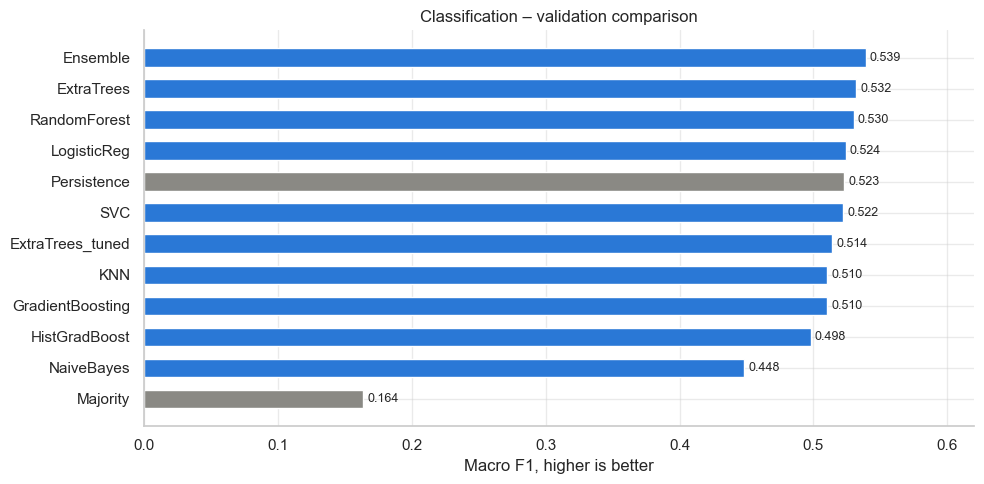

,F1_macro,Accuracy,Balanced_acc,F1_weighted
Ensemble,0.539,0.605,0.546,0.612
ExtraTrees,0.532,0.604,0.534,0.609
RandomForest,0.530,0.619,0.527,0.613
LogisticReg,0.524,0.584,0.547,0.593
Persistence,0.523,0.599,0.522,0.599
SVC,0.522,0.573,0.533,0.590
ExtraTrees_tuned,0.514,0.568,0.523,0.583
KNN,0.510,0.619,0.511,0.602
GradientBoosting,0.510,0.618,0.503,0.598
HistGradBoost,0.498,0.607,0.497,0.593


In [32]:
# 9.4 Soft-voting ensemble of the top three classifiers and choice of the final model
runners_up = clf_val_table["F1_macro"].drop(BASELINES + [clf_best], errors="ignore").index[:2]
clf_members = {n: wu.make_classifiers(SEED)[n] for n in runners_up} | {clf_best + "_tuned": clf_tuned}
print("Members:", list(clf_members))
clf_val_pred["Ensemble"] = wu.ensemble(clf_members).fit(X_train, y_train_c).predict(X_val)
f1_ens = wu.f1_macro(y_val_c, clf_val_pred["Ensemble"])
clf_final_name = "Ensemble" if f1_ens > f1_after else clf_best + "_tuned"
clf_final_recipe = wu.ensemble(clf_members) if clf_final_name == "Ensemble" else clone(clf_tuned)
print(f"Validation macro F1: {clf_best}_tuned {f1_after:.3f} | Ensemble {f1_ens:.3f} -> final: {clf_final_name}")

clf_val_full = pd.DataFrame({n: wu.classification_metrics(y_val_c, p) for n, p in clf_val_pred.items()}).T.sort_values("F1_macro", ascending=False).round(3)
clf_val_full.to_csv(RESULTS_DIR / "classification_validation_results.csv")

fig, ax = plt.subplots(figsize=(10, 5))
vals = clf_val_full["F1_macro"]
bars = ax.barh(vals.index, vals.values, height=0.6, color=[C_GRAY if n in BASELINES else C_BLUE for n in vals.index])
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, vals.max() * 1.15)
ax.set_xlabel("Macro F1, higher is better"); ax.set_title("Classification – validation comparison")
plt.tight_layout(); save_fig("clf_val_comparison"); plt.show()
clf_val_full

Tuning made extra trees worse on validation (0.532 to 0.514): the shallower trees (`max_depth=10`) that won on the 2014–2021 folds did not carry over to 2022–2023. The soft-voting ensemble of tuned extra trees, random forest and logistic regression reached 0.539 and became the final model under the rule fixed in advance. It mixes tree ensembles with a linear model, which err in different ways. Even so, the seven best candidates lie between 0.51 and 0.54, which points to a limit in the data rather than in the algorithms.

### Final evaluation on the test set

The final classifier is refitted on training and validation data and evaluated once on 2024–2025. The block bootstrap is applied to the difference in macro F1 against persistence.

In [33]:
# 9.5 Refit on train+validation and single test evaluation
clf_final = clf_final_recipe.fit(trainval[FEATURES], trainval["target_cond"])
joblib.dump(clf_final, MODELS_DIR / "final_classifier.joblib")
final_key = f"FINAL ({clf_final_name})"
clf_test_pred = {"Majority": np.full(len(test), trainval["target_cond"].mode()[0]),
                 "Persistence": wu.persistence_class(test), final_key: clf_final.predict(X_test)}
clf_test_table = pd.DataFrame({n: wu.classification_metrics(y_test_c, p) for n, p in clf_test_pred.items()}).T.round(3)
clf_test_table.to_csv(RESULTS_DIR / "classification_test_results.csv")

lo, hi = wu.block_bootstrap_diff(y_test_c.values, clf_test_pred["Persistence"], clf_test_pred[final_key], wu.f1_macro)
print(f"Macro F1 gain vs persistence, 95% CI [{lo:.3f}, {hi:.3f}] -> {'significant' if lo > 0 else 'not significant'}\n")
print(classification_report(y_test_c, clf_test_pred[final_key], labels=CLASSES, digits=3))
clf_test_table

Macro F1 gain vs persistence, 95% CI [-0.022, 0.045] -> not significant

               precision    recall  f1-score   support

        Clear      0.460     0.634     0.533       101
Partly Cloudy      0.311     0.282     0.296       131
       Cloudy      0.372     0.362     0.367       116
         Rain      0.833     0.783     0.808       383

     accuracy                          0.606       731
    macro avg      0.494     0.515     0.501       731
 weighted avg      0.615     0.606     0.608       731



,F1_macro,Accuracy,Balanced_acc,F1_weighted
Majority,0.172,0.524,0.250,0.360
Persistence,0.489,0.596,0.490,0.596
FINAL (Ensemble),0.501,0.606,0.515,0.608


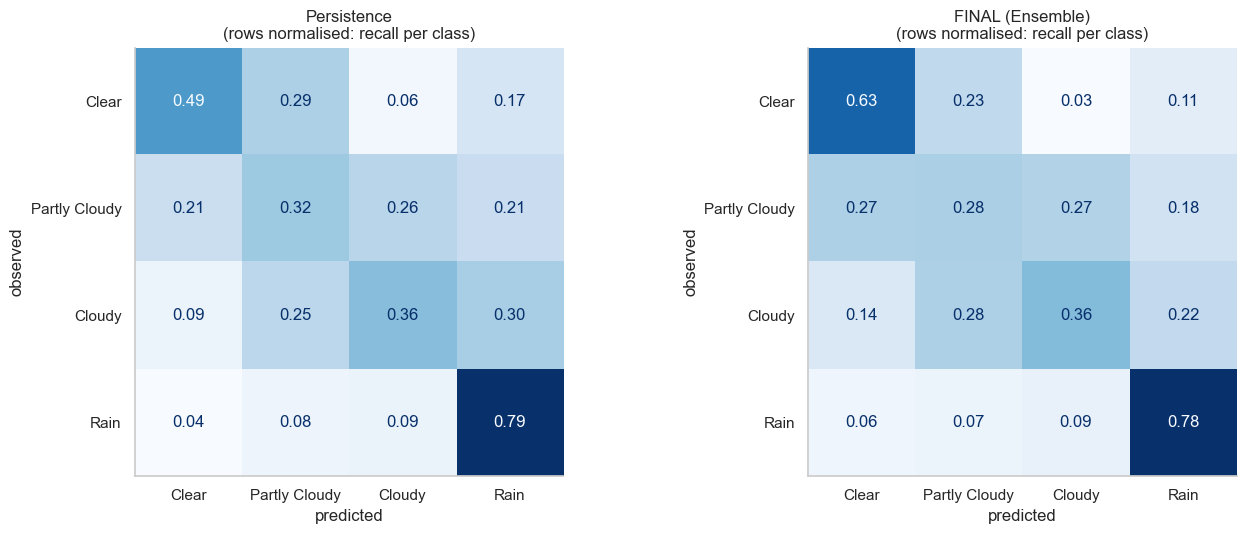

In [34]:
# 9.6 Test confusion matrices, row-normalised (diagonal = recall per class)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, ["Persistence", final_key]):
    cm = confusion_matrix(y_test_c, clf_test_pred[name], labels=CLASSES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{name}\n(rows normalised: recall per class)")
    ax.grid(False); ax.set_xlabel("predicted"); ax.set_ylabel("observed")
plt.tight_layout(); save_fig("clf_confusion_matrices"); plt.show()

On the test set the final model scores a macro F1 of 0.501 against 0.489 for persistence, with accuracy of 0.606 against 0.596. The bootstrap interval for the difference, [−0.022, 0.045], includes zero, so the improvement is not statistically supported, and for four-class prediction the model offers no proven advantage over assuming that tomorrow looks like today. Rain is predicted well (F1 0.81), while Clear, Partly Cloudy and Cloudy are confused with one another (F1 between 0.30 and 0.53). Their boundaries are cloud-cover thresholds, and days close to a threshold are almost indistinguishable. The model does raise the recall of Clear from 0.49 to 0.63, which is useful for planning outdoor activities.

### Rain or no rain

For most users the relevant question is whether it will rain. The predictions are collapsed into rain and no rain, and because the final model outputs probabilities, the ROC AUC (ability to rank wetter days above drier ones) and the Brier score (squared error of the probability) are also computed. The Brier score of a constant climatological probability serves as the reference.

In [35]:
# 9.7 Rain vs no rain on the test set and quality of the rain probability
rain_true = (y_test_c == "Rain").values
p_rain_model = clf_final.predict_proba(X_test)[:, list(clf_final.classes_).index("Rain")]
p_rain_clim = np.full(len(test), (trainval["target_cond"] == "Rain").mean())
print(f"ROC AUC of P(Rain), final model: {roc_auc_score(rain_true, p_rain_model):.3f}")
print(f"Brier score, final model:        {brier_score_loss(rain_true, p_rain_model):.3f}")
print(f"Brier score, climatology:        {brier_score_loss(rain_true, p_rain_clim):.3f}")
bin_table = pd.DataFrame({n: wu.rain_metrics(y_test_c, p) for n, p in clf_test_pred.items()}).T.round(3)
bin_table.to_csv(RESULTS_DIR / "rain_binary_test_results.csv")
bin_table

ROC AUC of P(Rain), final model: 0.884
Brier score, final model:        0.160
Brier score, climatology:        0.252


,Accuracy,Precision_rain,Recall_rain,F1_rain
Majority,0.524,0.524,1.000,0.688
Persistence,0.781,0.791,0.791,0.791
FINAL (Ensemble),0.804,0.833,0.783,0.808


As a yes/no forecast the model is only slightly better than persistence (accuracy 0.80 against 0.78, rain precision 0.83 against 0.79, rain F1 0.81 against 0.79). Its probabilities are where it adds value: the ROC AUC is 0.88 and the Brier score is 0.160 against 0.252 for climatology, a 37% reduction. This makes it possible to issue a forecast such as "80% chance of rain", which persistence cannot provide.

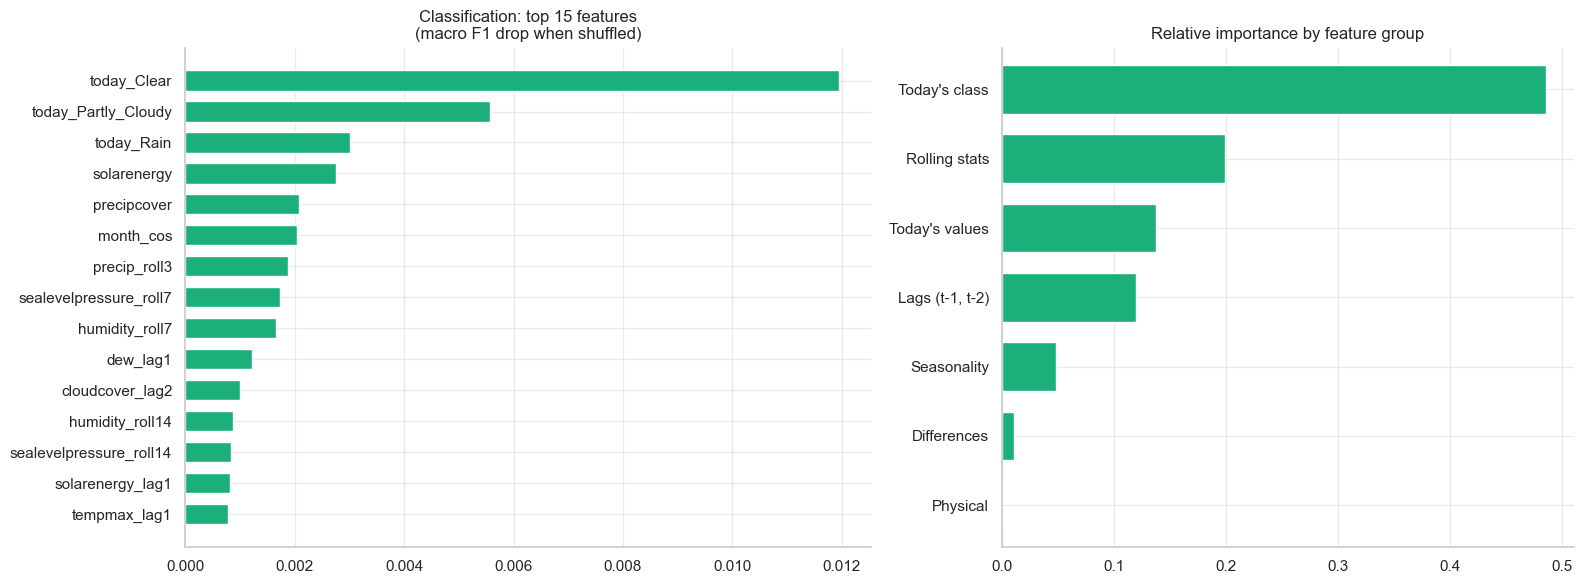

In [36]:
# 9.8 Permutation importance for the classifier (validation, macro F1)
pi = permutation_importance(clf_tuned, X_val, y_val_c, scoring="f1_macro", n_repeats=5, random_state=SEED, n_jobs=-1)
imp_c = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [1.2, 1]})
top = imp_c.head(15)[::-1]
axes[0].barh(top.index, top.values, color=C_AQUA, height=0.65)
axes[0].set_title("Classification: top 15 features\n(macro F1 drop when shuffled)")
g = imp_c.clip(lower=0).groupby(imp_c.index.map(wu.feature_group)).sum()
(g / g.sum()).sort_values().plot.barh(ax=axes[1], color=C_AQUA, width=0.7)
axes[1].set_title("Relative importance by feature group")
plt.tight_layout(); save_fig("clf_feature_importance"); plt.show()

Importance was measured on the tuned extra trees model, one of the ensemble members. Today's class is the most important group, with about half of the total, led by the Clear and Partly Cloudy indicators. It is followed by rolling statistics (rain over the last three days, pressure and humidity over the last week) and by today's solar energy and precipitation cover. In effect the model learns that tomorrow's sky resembles today's, adjusted for recent rain and humidity, pressure and season, which explains why it stays close to persistence.

---
## 10. Summary of test results

In [37]:
# 10.1 Summary built from the result tables
print(f"{LOCATION_NAME} | source: {DATA_SOURCE} | test targets 2024-01-01 to 2025-12-31")
for target, (_, label) in REG_TARGETS.items():
    t = reg_test_table.loc[label]
    fk = [k for k in t.index if k.startswith("FINAL")][0]
    print(f"\nRegression, tomorrow's {label} - {fk}")
    print(f"  MAE  {t.loc[fk, 'MAE']:.3f} °C (persistence {t.loc['Persistence', 'MAE']:.3f}, climatology {t.loc['Climatology', 'MAE']:.3f})")
    print(f"  RMSE {t.loc[fk, 'RMSE']:.3f} °C | R² {t.loc[fk, 'R2']:.3f} | r {t.loc[fk, 'Pearson_r']:.3f}")
    print(f"  Error reduction vs persistence: {1 - t.loc[fk, 'MAE'] / t.loc['Persistence', 'MAE']:.1%}")
c = clf_test_table
print(f"\nClassification, tomorrow's condition - {final_key}")
print(f"  Macro F1 {c.loc[final_key, 'F1_macro']:.3f} (persistence {c.loc['Persistence', 'F1_macro']:.3f}, majority {c.loc['Majority', 'F1_macro']:.3f})")
print(f"  Accuracy {c.loc[final_key, 'Accuracy']:.3f} (persistence {c.loc['Persistence', 'Accuracy']:.3f}, majority {c.loc['Majority', 'Accuracy']:.3f})")

Macau | source: Open-Meteo (ERA5) | test targets 2024-01-01 to 2025-12-31

Regression, tomorrow's Tmax - FINAL (Ensemble)
  MAE  1.220 °C (persistence 1.510, climatology 2.139)
  RMSE 1.605 °C | R² 0.884 | r 0.942
  Error reduction vs persistence: 19.2%

Regression, tomorrow's Tmin - FINAL (Ensemble)
  MAE  0.987 °C (persistence 1.107, climatology 1.790)
  RMSE 1.382 °C | R² 0.933 | r 0.967
  Error reduction vs persistence: 10.8%

Classification, tomorrow's condition - FINAL (Ensemble)
  Macro F1 0.501 (persistence 0.489, majority 0.172)
  Accuracy 0.606 (persistence 0.596, majority 0.524)


## 11. Discussion, limitations and future work

The models beat persistence because they combine today's state with its recent trend, the recent regime captured by rolling means, and the time of year. They can learn, for instance, that an unusually warm December day tends to be followed by a return towards normal, and that strong winds with a falling minimum temperature announce a north-east monsoon surge. Linear models were competitive throughout: for the maximum temperature Ridge and linear regression came within 0.002 °C of gradient boosting while training thousands of times faster. The wide comparison of models mattered more than tuning, since gradient boosting and extra trees, which were not among the three models considered at first, won on validation for the maximum temperature and for classification. Ensembling gave a consistent but small gain, largest when it combined different model families, and grid search gave essentially none.

The temperature improvements are of practical relevance: errors fall by 0.1 to 0.3 °C on average, by 11–19%, and by almost half a degree for the maximum in winter, when cold spells affect health, energy demand and agriculture. For four-class weather prediction no significant gain over persistence was found. Rainfall depends on synoptic systems such as fronts, troughs and typhoons that cannot be seen from one grid point, and the intermediate classes are separated by arbitrary cloud-cover thresholds. The rain probabilities, however, are clearly better than climatology.

The study has several limitations. It uses a single ERA5 grid point at roughly 25 km resolution, which smooths extremes and overstates drizzle (48% of days reach 1 mm), and the classes depend on thresholds chosen by the group. The data does not come from the source recommended in the specification, because the available Visual Crossing file contained only a 15-day forecast. The models have no spatial information and no numerical weather prediction input, rare events are scarce in the training data, and extremes are underestimated. The test period covers only two years, so ENSO phases or gradual warming could change the performance.

Natural extensions are adding neighbouring stations (Hong Kong, Zhuhai, Guangzhou) and climate indices such as ENSO; using hourly data to build late-afternoon pressure and humidity tendencies; producing probabilistic temperature forecasts with quantile regression and calibrating the rain probabilities; trying sequence models such as LSTMs; and evaluating with a walk-forward scheme that retrains every month, as an operational system would.

The system can support everyday planning in energy, schools and outdoor events, but it does not replace the warnings of the Macao Meteorological and Geophysical Bureau (SMG), particularly for typhoons and heavy rain, where a false "Clear" could have serious consequences. Forecasts should be issued with their uncertainty, for example a typical error of about ±1 °C and a probability of rain rather than a yes/no answer.